# Digital Advertising Budget Optimizer
## Notebook 06 — Budget Recommendation Engine

**Business question:** *Where should we spend the next Rs. 1,000,000?*

**Why not simply put everything on the platform with the best ROAS?** Notebook 02 showed that every platform has
**diminishing returns**: the more you spend on it, the less each extra rupee earns. The best home for the *next* rupee is the
platform with the highest **marginal ROAS** (return on the next rupee), not the highest *average* ROAS.

**Approach**
1. **Fit a response curve** per platform from 365 days of history: `revenue = a × spend^β` (β < 1 = diminishing returns)
2. **Validate the model** on held-out months and against the generator's answer key
3. **Optimise** the split of Rs. 1M to maximise expected revenue, within business limits
4. **Compare** the recommendation with common rules of thumb
5. **Measure confidence** with bootstrapping
6. **Show why big data matters**: how the recommendation's quality depends on dataset size

**Assumptions**
- The Rs. 1M is the budget for the next planning period, and platforms behave as they did over the last 12 months.
- Each platform responds to spend as observed in the daily data; platforms don't affect each other.
- The goal is revenue. With a fixed budget and a constant profit margin, maximising revenue also maximises gross profit.

**Requires:** Notebooks 01 and 02 completed. Runtime ~1 min.

In [1]:
# ============================================================
# 1. Setup
# ============================================================
import os, sys, json, time, importlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = "ad-budget-optimizer"
if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
else:
    DRIVE_DIR = Path.cwd() / PROJECT_NAME

SRC_DIR = DRIVE_DIR / "src"
FIG_DIR, REP_DIR = DRIVE_DIR / "outputs/figures", DRIVE_DIR / "outputs/reports"
sys.path.insert(0, str(SRC_DIR))
DAILY_PATH = DRIVE_DIR / "data/processed/daily_platform_10m.parquet"
assert DAILY_PATH.exists(), "Run Notebook 02 first (it creates the daily platform table)."
CONFIG = json.loads((DRIVE_DIR / "config/generator_config.json").read_text())
print("Ready:", DRIVE_DIR)

Mounted at /content/drive
Ready: /content/drive/MyDrive/ad-budget-optimizer


The engine lives in `src/engine.py` so it can be reused (e.g. re-run next month on new data).

In [2]:
%%writefile {SRC_DIR}/engine.py
"""
engine.py: Marketing budget recommendation engine.

Model
-----
Each platform's daily revenue follows a diminishing-returns response curve

    revenue = a * spend ** beta        (0 < beta < 1: each extra rupee earns less)

fitted on daily spend/revenue history with a log-log regression.

Planning
--------
Curves are anchored at each platform's usual spend: at its historical budget share a
platform earns its usual ROAS. Moving budget share w away from the historical share h
changes its ROAS by the factor (w / h) ** (beta - 1). The optimiser splits a budget to
maximise total expected revenue within business limits (minimum and maximum share).
The recommended split does not depend on the size of the budget.
"""
import numpy as np
import pandas as pd
from scipy.optimize import minimize


# ----------------------------------------------------------------------------
# Fitting
# ----------------------------------------------------------------------------
def fit_curve(spend, revenue):
    """Log-log least squares. Returns beta, log_a, R^2 (on log scale)."""
    x, y = np.log(spend), np.log(revenue)
    beta, log_a = np.polyfit(x, y, 1)
    resid = y - (log_a + beta * x)
    r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return beta, log_a, r2


def fit_all(daily):
    """daily: DataFrame with columns platform, spend, revenue (one row per platform per day)."""
    d = daily[(daily.spend > 0) & (daily.revenue > 0)]
    total = d.spend.sum()
    rows = []
    for p, g in d.groupby("platform", observed=True):
        beta, log_a, r2 = fit_curve(g.spend.values, g.revenue.values)
        usual = g.spend.mean()
        rows.append({"platform": str(p), "beta": beta,
                     "roas_at_usual": np.exp(log_a) * usual ** (beta - 1),
                     "hist_share": g.spend.sum() / total, "r2": r2, "days": len(g),
                     "log_a": log_a, "usual_daily_spend": usual})
    return pd.DataFrame(rows).set_index("platform")


def predict_daily_revenue(params, platform, spend):
    p = params.loc[platform]
    return np.exp(p.log_a) * np.asarray(spend) ** p.beta


# ----------------------------------------------------------------------------
# Planning
# ----------------------------------------------------------------------------
def _arr(shares, params):
    if isinstance(shares, (pd.Series, dict)):
        return pd.Series(shares).reindex(params.index).values.astype(float)
    return np.asarray(shares, dtype=float)


def expected_revenue(shares, params, budget):
    """Expected revenue per platform when `budget` is split by `shares`."""
    w = np.clip(_arr(shares, params), 1e-12, None)
    h, r, b = params.hist_share.values, params.roas_at_usual.values, params.beta.values
    return pd.Series(budget * h * r * (w / h) ** b, index=params.index)


def marginal_roas(shares, params):
    """Revenue from the NEXT rupee on each platform at the given split."""
    w = np.clip(_arr(shares, params), 1e-12, None)
    h, r, b = params.hist_share.values, params.roas_at_usual.values, params.beta.values
    return pd.Series(r * b * (w / h) ** (b - 1), index=params.index)


def optimise(params, min_share=0.0, max_share=1.0):
    """Shares that maximise expected revenue, with sum = 1 and per-platform bounds.
    min_share / max_share can be a number or a dict {platform: value}."""
    idx = params.index
    lo = pd.Series(min_share, index=idx) if np.isscalar(min_share) else pd.Series(min_share).reindex(idx).fillna(0.0)
    hi = pd.Series(max_share, index=idx) if np.isscalar(max_share) else pd.Series(max_share).reindex(idx).fillna(1.0)
    h, r, b = params.hist_share.values, params.roas_at_usual.values, params.beta.values

    def obj(w):
        w = np.clip(w, 1e-12, None)
        return -(h * r * (w / h) ** b).sum()

    def grad(w):
        w = np.clip(w, 1e-12, None)
        return -(r * b * (w / h) ** (b - 1))

    x0 = np.clip(h, lo.values, hi.values)
    x0 = x0 / x0.sum()
    res = minimize(obj, x0, jac=grad, method="SLSQP",
                   bounds=list(zip(lo.values, hi.values)),
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones_like(w)}],
                   options={"ftol": 1e-12, "maxiter": 1000})
    if not res.success:
        raise RuntimeError(f"Optimiser failed: {res.message}")
    return pd.Series(res.x, index=idx)


def round_budget(shares, budget, step=5000):
    """Turn shares into Rs amounts rounded to `step` that still add up exactly to `budget`."""
    units = int(round(budget / step))
    raw = shares.values * units
    base = np.floor(raw).astype(int)
    for i in np.argsort(-(raw - base))[: units - base.sum()]:
        base[i] += 1
    return pd.Series(base * step, index=shares.index)


def bootstrap_shares(daily, n=200, seed=42, **opt_kwargs):
    """Refit and re-optimise on resampled days to measure how stable the recommendation is."""
    S = daily.pivot(index="date", columns="platform", values="spend")
    R = daily.pivot(index="date", columns="platform", values="revenue")
    S, R = S.loc[:, S.columns.astype(str)], R.loc[:, R.columns.astype(str)]
    rng = np.random.default_rng(seed)
    days = len(S)
    out = []
    for _ in range(n):
        i = rng.integers(0, days, days)
        sample = pd.DataFrame({"spend": S.iloc[i].stack(), "revenue": R.iloc[i].stack()}).reset_index()
        out.append(optimise(fit_all(sample), **opt_kwargs))
    return pd.DataFrame(out)

Writing /content/drive/MyDrive/ad-budget-optimizer/src/engine.py


In [3]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown
import engine, kpis, viz
for m in (engine, kpis, viz):
    importlib.reload(m)
viz.apply_style()
pd.set_option("display.width", 200)
ORDER = viz.PLATFORM_ORDER

daily = pd.read_parquet(DAILY_PATH)
daily["platform"] = daily.platform.astype(str)
print(f"Daily history: {len(daily):,} rows = {daily.date.nunique()} days x {daily.platform.nunique()} platforms "
      f"(aggregated from 10M records in Notebook 02)")

Daily history: 1,825 rows = 365 days x 5 platforms (aggregated from 10M records in Notebook 02)


## 2. Planning settings
Business limits keep the plan realistic. Change them here and re-run the notebook to explore other policies.

| Setting | Value | Reason |
|---|---|---|
| Minimum per platform | 5% | Stay visible on every channel, keep testing, protect brand presence |
| Maximum per platform | 40% | Don't depend on one channel (algorithm changes, price spikes, account bans) |

In [4]:
BUDGET = 1_000_000      # Rs.
MIN_SHARE = 0.05
MAX_SHARE = 0.40
ROUND_TO = 5_000        # final amounts rounded to Rs. 5,000

## 3. Step 1: Response curves
For each platform, a straight line is fitted to log(daily revenue) vs log(daily spend). The slope is **β**:
- β = 1 → no saturation: doubling spend doubles revenue
- β = 0.7 → doubling spend multiplies revenue by 2^0.7 = 1.62, so ROAS falls by 19%

,beta,ROAS at usual spend,roas_change_if_spend_doubles_%,current share,R² (fit quality),days
platform,,,,,,
Facebook,0.804,3.196,-12.728,0.30,0.960,365
Instagram,0.756,3.555,-15.586,0.25,0.956,365
Google,0.652,4.528,-21.410,0.20,0.937,365
TikTok,0.854,2.623,-9.620,0.15,0.961,365
YouTube,0.800,1.818,-12.918,0.10,0.949,365


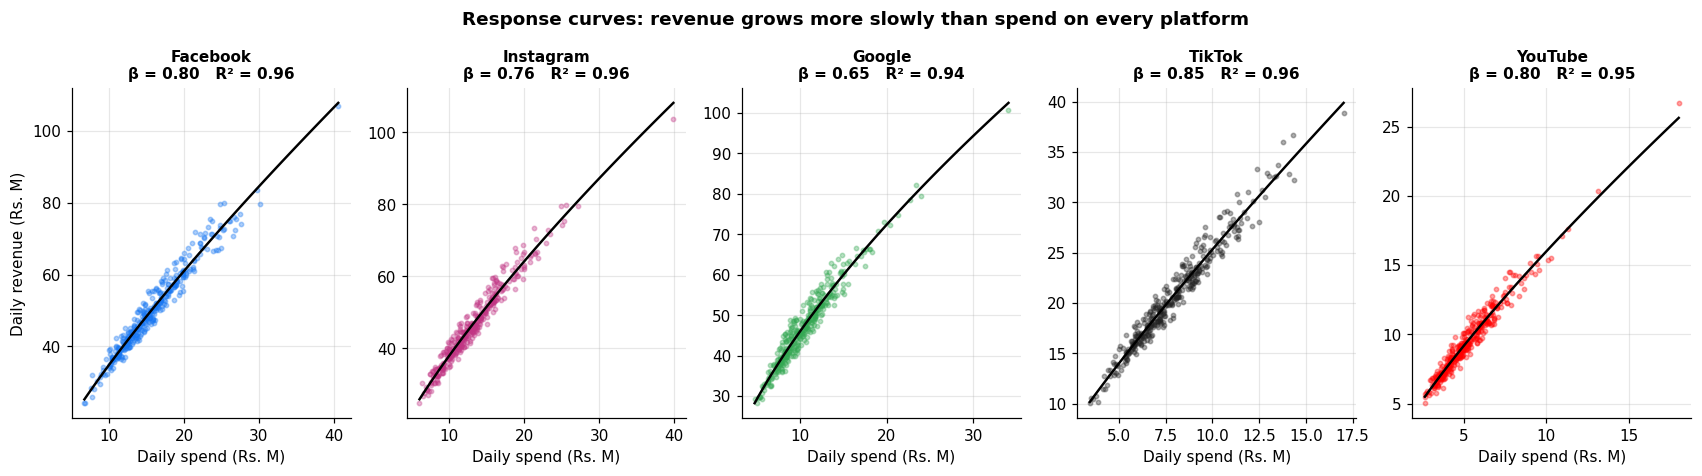

In [5]:
params = engine.fit_all(daily).reindex(ORDER)
params["roas_change_if_spend_doubles_%"] = 100 * (2 ** (params.beta - 1) - 1)
params.to_csv(REP_DIR / "06_response_curves.csv")
display(params[["beta", "roas_at_usual", "roas_change_if_spend_doubles_%", "hist_share", "r2", "days"]]
        .rename(columns={"roas_at_usual": "ROAS at usual spend", "hist_share": "current share",
                         "r2": "R² (fit quality)"}).round(3))

fig, ax = plt.subplots(1, 5, figsize=(19, 3.9))
for a, p in zip(ax, ORDER):
    g = daily[daily.platform == p]
    a.scatter(g.spend / 1e6, g.revenue / 1e6, s=8, alpha=0.35, color=viz.PLATFORM_COLORS[p])
    xs = np.linspace(g.spend.min(), g.spend.max(), 100)
    a.plot(xs / 1e6, engine.predict_daily_revenue(params, p, xs) / 1e6, color="black", lw=1.6)
    a.set_title(f"{p}\nβ = {params.beta[p]:.2f}   R² = {params.r2[p]:.2f}", fontsize=10)
    a.set_xlabel("Daily spend (Rs. M)")
ax[0].set_ylabel("Daily revenue (Rs. M)")
fig.suptitle("Response curves: revenue grows more slowly than spend on every platform", fontweight="bold", y=1.06)
viz.save(fig, FIG_DIR, "06_response_curves"); plt.show()

## 4. Step 2: Can we trust the model?
**Test A: Hold-out back-test.** Fit on Nov 2025 – Aug 2026, then predict daily revenue for Sep – Oct 2026, which the model has never seen.
It is compared with the simple "constant ROAS" assumption most spreadsheets use (revenue = average ROAS × spend).

**Test B: Answer key.** The data is synthetic, so the true market rules are known (Notebook 01's `generator_config.json`).
A correct engine should recover them from the data alone.

Test A: daily revenue prediction error on unseen months (lower is better)


,test_days,MAPE_curve_%,MAPE_constant_ROAS_%,error_reduction_%
platform,,,,
Facebook,61,3.42,5.40,36.60
Instagram,61,3.42,5.89,42.00
Google,61,3.36,8.31,59.59
TikTok,61,3.99,5.20,23.29
YouTube,61,4.52,6.27,27.82


Test B: fitted vs true market parameters


,beta_fitted,beta_true,roas_fitted,roas_true,beta_error_%,roas_error_%
Facebook,0.804,0.80,3.196,3.200,0.450,-0.119
Instagram,0.756,0.75,3.555,3.556,0.741,-0.018
Google,0.652,0.65,4.528,4.533,0.371,-0.109
TikTok,0.854,0.85,2.623,2.629,0.479,-0.230
YouTube,0.800,0.80,1.818,1.824,0.057,-0.342


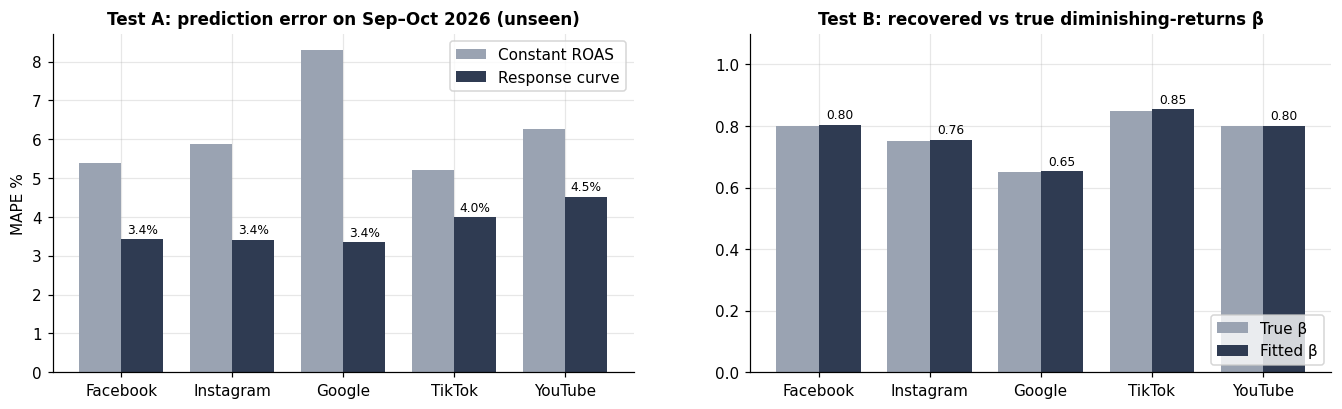

In [6]:
cut = pd.Timestamp("2026-09-01")
train, test = daily[daily.date < cut], daily[daily.date >= cut]
p_train = engine.fit_all(train)
bt = []
for p in ORDER:
    t = test[test.platform == p]
    tr = train[train.platform == p]
    curve = engine.predict_daily_revenue(p_train, p, t.spend.values)
    const = t.spend.values * tr.revenue.sum() / tr.spend.sum()
    mape = lambda pred: 100 * np.mean(np.abs(pred - t.revenue.values) / t.revenue.values)
    bt.append({"platform": p, "test_days": len(t), "MAPE_curve_%": mape(curve), "MAPE_constant_ROAS_%": mape(const)})
backtest = pd.DataFrame(bt).set_index("platform")
backtest["error_reduction_%"] = 100 * (1 - backtest["MAPE_curve_%"] / backtest["MAPE_constant_ROAS_%"])
print("Test A: daily revenue prediction error on unseen months (lower is better)")
display(backtest.round(2))

truth = pd.DataFrame({p: {"beta": v["beta"], "roas_at_usual": v["baseline_roas"], "hist_share": v["hist_share"]}
                      for p, v in CONFIG["platforms"].items()}).T.reindex(ORDER).astype(float)
key = pd.DataFrame({"beta_fitted": params.beta, "beta_true": truth.beta,
                    "roas_fitted": params.roas_at_usual, "roas_true": truth.roas_at_usual})
key["beta_error_%"] = 100 * (key.beta_fitted / key.beta_true - 1)
key["roas_error_%"] = 100 * (key.roas_fitted / key.roas_true - 1)
print("Test B: fitted vs true market parameters")
display(key.round(3))
pd.concat([backtest, key], axis=1).to_csv(REP_DIR / "06_validation.csv")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
x, w = np.arange(len(ORDER)), 0.38
ax[0].bar(x - w/2, backtest["MAPE_constant_ROAS_%"], w, color=viz.NEUTRAL, label="Constant ROAS")
b = ax[0].bar(x + w/2, backtest["MAPE_curve_%"], w, color=viz.ACCENT, label="Response curve")
ax[0].bar_label(b, fmt="%.1f%%", padding=2, fontsize=8)
ax[0].set_xticks(x, ORDER); ax[0].set_ylabel("MAPE %")
ax[0].set_title("Test A: prediction error on Sep–Oct 2026 (unseen)"); ax[0].legend()
ax[1].bar(x - w/2, key.beta_true, w, color=viz.NEUTRAL, label="True β")
b = ax[1].bar(x + w/2, key.beta_fitted, w, color=viz.ACCENT, label="Fitted β")
ax[1].bar_label(b, fmt="%.2f", padding=2, fontsize=8)
ax[1].set_xticks(x, ORDER); ax[1].set_ylim(0, 1.1)
ax[1].set_title("Test B: recovered vs true diminishing-returns β"); ax[1].legend(loc="lower right")
viz.save(fig, FIG_DIR, "06_model_validation"); plt.show()

## 5. Step 3: Optimise the split
The optimiser shifts budget between platforms until the **next rupee earns the same everywhere** (equal marginal ROAS),
except where a business limit stops it. If one platform's next rupee earned more than another's, moving money
towards it would raise total revenue, so the plan wasn't optimal yet.

,current_%,recommended_%,no_limits_%,marginal_ROAS_now,marginal_ROAS_recommended
platform,,,,,
Facebook,30.00,29.69,31.37,2.57,2.57
Instagram,24.99,29.77,31.11,2.69,2.57
Google,20.01,29.75,30.68,2.95,2.57
TikTok,15.00,5.79,6.24,2.24,2.57
YouTube,10.00,5.00,0.61,1.46,1.67


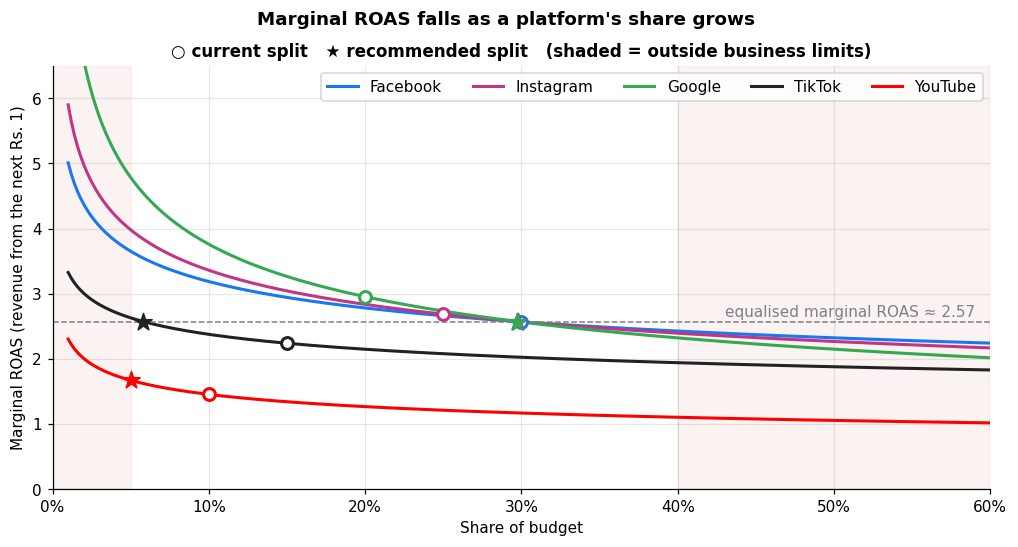

In [7]:
current = params.hist_share
recommended = engine.optimise(params, MIN_SHARE, MAX_SHARE).reindex(ORDER)
unconstrained = engine.optimise(params).reindex(ORDER)

opt = pd.DataFrame({
    "current_%": 100 * current,
    "recommended_%": 100 * recommended,
    "no_limits_%": 100 * unconstrained,
    "marginal_ROAS_now": engine.marginal_roas(current, params),
    "marginal_ROAS_recommended": engine.marginal_roas(recommended, params),
}).reindex(ORDER)
display(opt.round(2))

lam = float(np.median(opt.marginal_ROAS_recommended))
fig, ax = plt.subplots(figsize=(11, 5))
ws = np.linspace(0.01, 0.6, 300)
for p in ORDER:
    c = viz.PLATFORM_COLORS[p]
    curve = [engine.marginal_roas(pd.Series({q: (w if q == p else params.hist_share[q]) for q in ORDER}), params)[p]
             for w in ws]
    ax.plot(ws * 100, curve, color=c, lw=2, label=p)
    ax.scatter(100 * current[p], opt.marginal_ROAS_now[p], color=c, s=60, facecolors="white", linewidths=2, zorder=3)
    ax.scatter(100 * recommended[p], opt.marginal_ROAS_recommended[p], color=c, s=140, marker="*", zorder=4)
ax.axhline(lam, color="grey", ls="--", lw=1)
ax.text(59, lam * 1.03, f"equalised marginal ROAS ≈ {lam:.2f}", ha="right", color="grey")
ax.axvspan(0, MIN_SHARE * 100, color="#C62828", alpha=0.06)
ax.axvspan(MAX_SHARE * 100, 60, color="#C62828", alpha=0.06)
ax.set_ylim(0, 6.5); ax.set_xlim(0, 60)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Share of budget"); ax.set_ylabel("Marginal ROAS (revenue from the next Rs. 1)")
ax.set_title("○ current split   ★ recommended split   (shaded = outside business limits)")
ax.legend(ncol=5, loc="upper right")
fig.suptitle("Marginal ROAS falls as a platform's share grows", fontweight="bold")
viz.save(fig, FIG_DIR, "06_marginal_roas"); plt.show()

## 6. Step 4: Recommendation vs rules of thumb
Every plan below spends exactly Rs. 1,000,000, evaluated with the fitted response curves.

,Facebook,Instagram,Google,TikTok,YouTube,expected_revenue_Rs,ROAS,vs_current_Rs,vs_current_%
scenario,,,,,,,,,
Current split,30.0,25.0,20.0,15.0,10.0,3328542.1,3.3,0.0,0.0
Equal split (20% each),20.0,20.0,20.0,20.0,20.0,3168441.8,3.2,-160100.3,-4.8
Proportional to ROAS,20.3,22.6,28.8,16.7,11.6,3309557.4,3.3,-18984.7,-0.6
Top-ROAS first (40% cap),10.0,40.0,40.0,5.0,5.0,3346177.8,3.3,17635.6,0.5
All on Google (best avg ROAS),0.0,0.0,100.0,0.0,0.0,2588323.2,2.6,-740219.0,-22.2
Recommended (optimised),29.7,29.8,29.7,5.8,5.0,3417437.0,3.4,88894.9,2.7


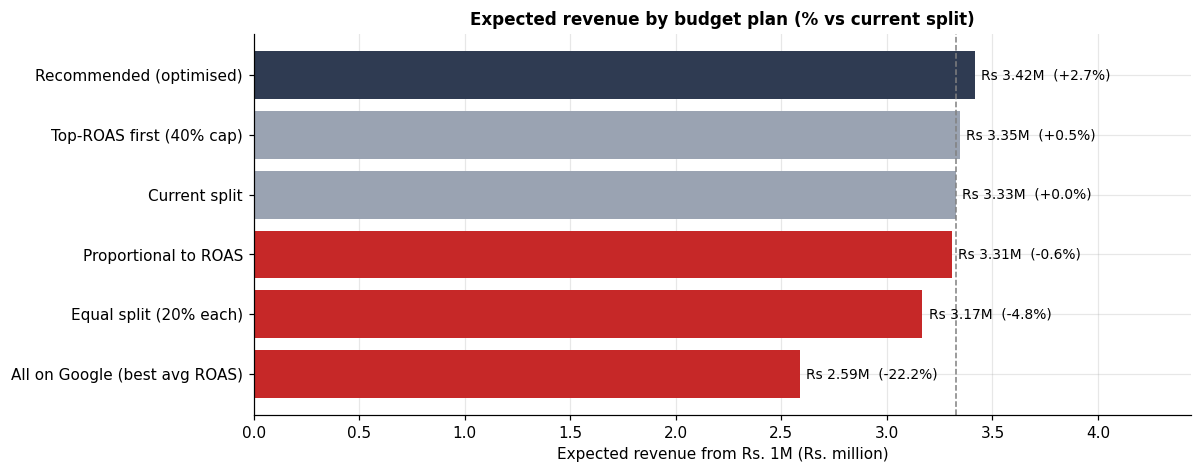

In [8]:
def greedy(params, lo, hi):
    """Fill the highest-average-ROAS platforms first (a common rule of thumb)."""
    w = pd.Series(lo, index=params.index)
    left = 1 - w.sum()
    for p in params.roas_at_usual.sort_values(ascending=False).index:
        add = min(hi - lo, left)
        w[p] += add
        left -= add
    return w

best_avg = params.roas_at_usual.idxmax()
scenarios = {
    "Current split": current,
    "Equal split (20% each)": pd.Series(0.2, index=ORDER),
    "Proportional to ROAS": params.roas_at_usual / params.roas_at_usual.sum(),
    f"Top-ROAS first ({int(MAX_SHARE * 100)}% cap)": greedy(params, MIN_SHARE, MAX_SHARE),
    f"All on {best_avg} (best avg ROAS)": pd.Series({p: float(p == best_avg) for p in ORDER}),
    "Recommended (optimised)": recommended,
}
base_rev = engine.expected_revenue(current, params, BUDGET).sum()
sc = pd.DataFrame([{"scenario": name, **{p: 100 * w[p] for p in ORDER},
                    "expected_revenue_Rs": engine.expected_revenue(w, params, BUDGET).sum()}
                   for name, w in scenarios.items()]).set_index("scenario")
sc["ROAS"] = sc.expected_revenue_Rs / BUDGET
sc["vs_current_Rs"] = sc.expected_revenue_Rs - base_rev
sc["vs_current_%"] = 100 * (sc.expected_revenue_Rs / base_rev - 1)
sc.to_csv(REP_DIR / "06_scenarios.csv")
display(sc.round(1))

fig, ax = plt.subplots(figsize=(11, 4.5))
s = sc.sort_values("expected_revenue_Rs")
colors = [viz.ACCENT if "Recommended" in i else ("#C62828" if v < 0 else viz.NEUTRAL)
          for i, v in zip(s.index, s["vs_current_%"])]
b = ax.barh(s.index, s.expected_revenue_Rs / 1e6, color=colors)
ax.bar_label(b, labels=[f"Rs {v / 1e6:.2f}M  ({d:+.1f}%)" for v, d in zip(s.expected_revenue_Rs, s["vs_current_%"])],
             padding=4, fontsize=9)
ax.axvline(base_rev / 1e6, color="grey", ls="--", lw=1)
ax.set_xlim(0, s.expected_revenue_Rs.max() / 1e6 * 1.3)
ax.set_xlabel("Expected revenue from Rs. 1M (Rs. million)")
ax.set_title("Expected revenue by budget plan (% vs current split)")
viz.save(fig, FIG_DIR, "06_scenarios"); plt.show()

## 7. Step 5: How confident are we?
**Bootstrapping:** re-run the whole engine 200 times, each time on a random resample of the 365 days.
If the recommended split barely moves, it is driven by the data rather than by a few unusual days.

In [9]:
t0 = time.time()
boot = engine.bootstrap_shares(daily, n=200, min_share=MIN_SHARE, max_share=MAX_SHARE)[ORDER]
boot.to_csv(REP_DIR / "06_bootstrap_shares.csv", index=False)
ci = pd.DataFrame({"recommended_%": 100 * recommended, "low_95_%": 100 * boot.quantile(0.025),
                   "high_95_%": 100 * boot.quantile(0.975)}).round(1)
print(f"200 bootstrap runs in {time.time() - t0:.1f}s")
display(ci)

200 bootstrap runs in 3.3s


,recommended_%,low_95_%,high_95_%
platform,,,
Facebook,29.7,27.5,32.3
Instagram,29.8,27.6,32.2
Google,29.7,28.1,31.6
TikTok,5.8,5.3,6.4
YouTube,5.0,5.0,5.0


## 8. Step 6: Why big data matters here
The same engine, fed with each dataset size from Notebook 01. Because the true market rules are known,
we can measure how much of the **best possible** revenue gain each recommendation actually captures.

,Facebook_%,Instagram_%,Google_%,TikTok_%,YouTube_%,true_gain_Rs,share_of_best_gain_%
dataset,,,,,,,
10k,10.0,40.0,40.0,5.0,5.0,13364.4,15.3
100k,22.6,28.5,38.9,5.0,5.0,70502.6,81.0
1m,29.8,29.4,30.3,5.6,5.0,86968.5,99.9
10m,29.7,29.8,29.7,5.8,5.0,87030.4,100.0


Fitted β by dataset size


,Facebook,Instagram,Google,TikTok,YouTube
dataset,,,,,
10k,1.01,0.97,0.98,0.93,0.58
100k,0.87,0.85,0.76,0.91,0.91
1m,0.81,0.76,0.66,0.86,0.80
10m,0.80,0.76,0.65,0.85,0.80
true value,0.80,0.75,0.65,0.85,0.80


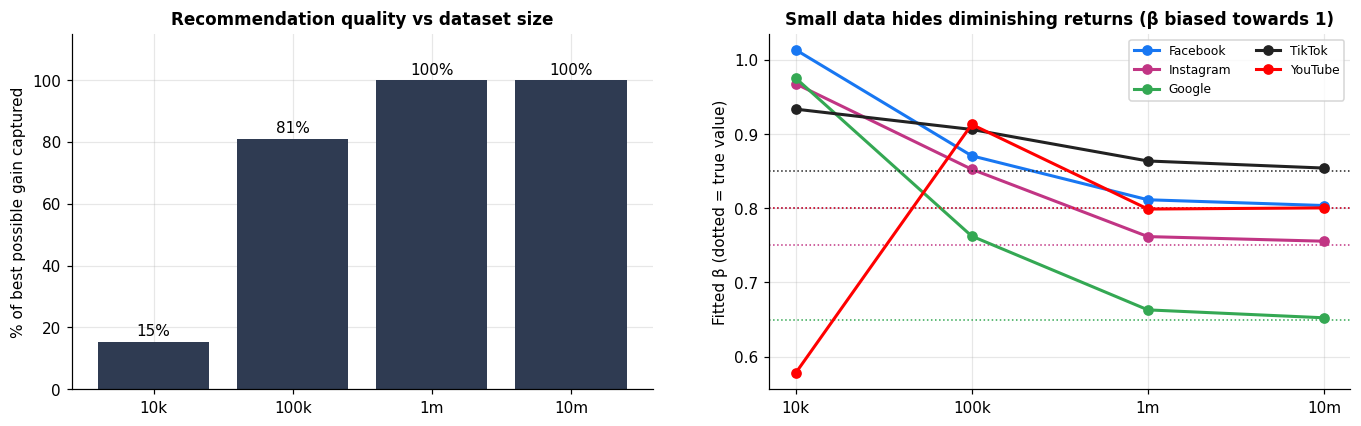

In [10]:
def daily_from(label):
    if label == "10m":
        return daily
    t = (pq.read_table(DRIVE_DIR / f"data/raw/parquet/ads_{label}", columns=["date", "platform", "spend", "revenue"])
           .group_by(["date", "platform"]).aggregate([("spend", "sum"), ("revenue", "sum")]).to_pandas()
           .rename(columns={"spend_sum": "spend", "revenue_sum": "revenue"}))
    t["platform"] = t.platform.astype(str)
    return t

true_current = engine.expected_revenue(truth.hist_share, truth, BUDGET).sum()
true_best = engine.expected_revenue(engine.optimise(truth, MIN_SHARE, MAX_SHARE), truth, BUDGET).sum()
size_rows = []
for label, n in [("10k", 10_000), ("100k", 100_000), ("1m", 1_000_000), ("10m", 10_000_000)]:
    p_ = engine.fit_all(daily_from(label)).reindex(ORDER)
    w_ = engine.optimise(p_, MIN_SHARE, MAX_SHARE).reindex(ORDER)
    rev = engine.expected_revenue(w_, truth, BUDGET).sum()          # judged by the TRUE market
    size_rows.append({"dataset": label, "rows": n, **{f"beta_{p}": p_.beta[p] for p in ORDER},
                      **{f"{p}_%": 100 * w_[p] for p in ORDER},
                      "true_gain_Rs": rev - true_current,
                      "share_of_best_gain_%": 100 * (rev - true_current) / (true_best - true_current)})
sizes = pd.DataFrame(size_rows).set_index("dataset")
sizes.to_csv(REP_DIR / "06_data_size_sensitivity.csv")
display(sizes[[f"{p}_%" for p in ORDER] + ["true_gain_Rs", "share_of_best_gain_%"]].round(1))
beta_tbl = sizes[[f"beta_{p}" for p in ORDER]].copy()
beta_tbl.columns = ORDER
beta_tbl.loc["true value"] = truth.beta
print("Fitted β by dataset size")
display(beta_tbl.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
b = ax[0].bar(sizes.index, sizes["share_of_best_gain_%"], color=viz.ACCENT)
ax[0].bar_label(b, fmt="%.0f%%", padding=2)
ax[0].set_ylim(0, 115); ax[0].set_ylabel("% of best possible gain captured")
ax[0].set_title("Recommendation quality vs dataset size")
for p in ORDER:
    ax[1].plot(sizes.index, sizes[f"beta_{p}"], "o-", color=viz.PLATFORM_COLORS[p], lw=2, label=p)
    ax[1].axhline(truth.beta[p], color=viz.PLATFORM_COLORS[p], ls=":", lw=1)
ax[1].set_ylabel("Fitted β (dotted = true value)")
ax[1].set_title("Small data hides diminishing returns (β biased towards 1)")
ax[1].legend(fontsize=8, ncol=2)
viz.save(fig, FIG_DIR, "06_data_size"); plt.show()

With little data, each platform-day is built from only a handful of records, so random noise in the number of records
makes spend and revenue move together and hides the saturation (β looks close to 1). The engine then over-trusts average ROAS
and recommends a much worse plan. **More data didn't just make processing harder; it made the business answer correct.**

## 9. Final recommendation

,Current (Rs),Recommended (Rs),Change (Rs),Share %,95% range %,Expected revenue (Rs),Expected ROAS
Facebook,"300,000","295,000","-5,000",29.5,28–32,"946,000",3.21
Instagram,"250,000","300,000","+50,000",30.0,28–32,"1,020,000",3.40
Google,"200,000","295,000","+95,000",29.5,28–32,"1,167,000",3.96
TikTok,"150,000","60,000","-90,000",6.0,5–6,"180,000",3.00
YouTube,"100,000","50,000","-50,000",5.0,5–5,"104,000",2.09
TOTAL,"1,000,000","1,000,000",+0,100.0,,"3,417,000",3.42


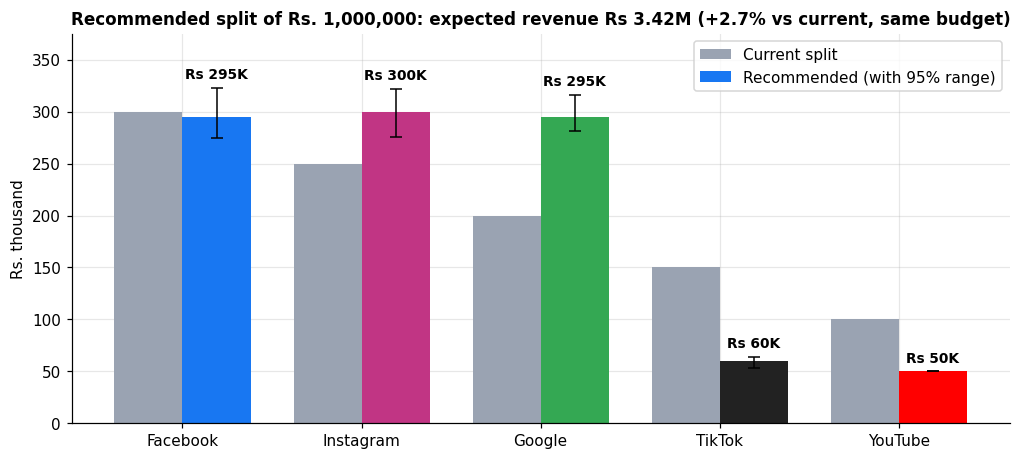

In [11]:
amounts = engine.round_budget(recommended, BUDGET, ROUND_TO).reindex(ORDER)
exp_rev = engine.expected_revenue(amounts / BUDGET, params, BUDGET)
cur_amt = (current * BUDGET).round(-3)
final = pd.DataFrame({
    "Current (Rs)": cur_amt,
    "Recommended (Rs)": amounts,
    "Change (Rs)": amounts - cur_amt,
    "Share %": 100 * amounts / BUDGET,
    "95% range %": [f"{ci.loc[p, 'low_95_%']:.0f}–{ci.loc[p, 'high_95_%']:.0f}" for p in ORDER],
    "Expected revenue (Rs)": exp_rev.round(-3),
    "Expected ROAS": exp_rev / amounts,
})
total = pd.DataFrame({"Current (Rs)": [cur_amt.sum()], "Recommended (Rs)": [amounts.sum()], "Change (Rs)": [0],
                      "Share %": [100.0], "95% range %": [""], "Expected revenue (Rs)": [exp_rev.sum().round(-3)],
                      "Expected ROAS": [exp_rev.sum() / BUDGET]}, index=["TOTAL"])
final_tbl = pd.concat([final, total])
final_tbl.to_csv(REP_DIR / "06_recommendation.csv")
display(final_tbl.style.format({"Current (Rs)": "{:,.0f}", "Recommended (Rs)": "{:,.0f}", "Change (Rs)": "{:+,.0f}",
                                "Share %": "{:.1f}", "Expected revenue (Rs)": "{:,.0f}", "Expected ROAS": "{:.2f}"}))

rec_rev = exp_rev.sum()
uplift_rs, uplift_pct = rec_rev - base_rev, 100 * (rec_rev / base_rev - 1)

fig, ax = plt.subplots(figsize=(11, 4.6))
x, w = np.arange(len(ORDER)), 0.38
ax.bar(x - w/2, cur_amt / 1e3, w, color=viz.NEUTRAL, label="Current split")
ax.bar(x + w/2, amounts / 1e3, w, color=viz.colors_for(ORDER), label="Recommended (with 95% range)")
err = np.array([(amounts[p] - ci.loc[p, "low_95_%"] * BUDGET / 100, ci.loc[p, "high_95_%"] * BUDGET / 100 - amounts[p])
                for p in ORDER]).clip(0).T / 1e3
ax.errorbar(x + w/2, amounts / 1e3, yerr=err, fmt="none", ecolor="black", capsize=4, lw=1)
for xi, v, hi in zip(x + w/2, amounts / 1e3, err[1]):
    ax.text(xi, v + hi + 6, f"Rs {v:,.0f}K", ha="center", va="bottom", fontweight="bold", fontsize=9)
ax.set_ylim(0, max(cur_amt.max(), amounts.max()) / 1e3 * 1.25)
ax.set_xticks(x, ORDER); ax.set_ylabel("Rs. thousand")
ax.set_title(f"Recommended split of Rs. {BUDGET:,}: expected revenue Rs {rec_rev / 1e6:.2f}M "
             f"({uplift_pct:+.1f}% vs current, same budget)")
ax.legend()
viz.save(fig, FIG_DIR, "06_final_recommendation"); plt.show()

### Where to spend within each platform
The engine decides **how much** each platform gets; Notebook 02's results show **where** inside each platform to spend it
(based on average performance).

In [ ]:
camp = pd.read_csv(REP_DIR / "02_kpi_campaign.csv", index_col=0)
by_type = camp.groupby(["platform", "type"])[kpis.METRICS].sum()
by_type["ROAS"] = by_type.revenue / by_type.spend
age = pd.read_csv(REP_DIR / "02_roas_platform_x_age.csv", index_col=0)
device = kpis.kpi_table(pd.read_csv(REP_DIR / "02_kpi_device.csv", index_col=0)[kpis.METRICS].reset_index(), "device")
city = pd.read_csv(REP_DIR / "02_kpi_city.csv", index_col=0).sort_values("ROAS", ascending=False)

guide = []
for p in ORDER:
    t = by_type.loc[p].sort_values("ROAS", ascending=False)
    guide.append({"platform": p, "budget (Rs)": f"{amounts[p]:,.0f}",
                  "prioritise": f"{t.index[0]} (ROAS {t.ROAS.iloc[0]:.1f}), {t.index[1]} ({t.ROAS.iloc[1]:.1f})",
                  "limit": f"{t.index[-1]} (ROAS {t.ROAS.iloc[-1]:.1f})",
                  "best age group": f"{age.loc[p].idxmax()} (ROAS {age.loc[p].max():.1f})"})
guide = pd.DataFrame(guide).set_index("platform")
guide.to_csv(REP_DIR / "06_within_platform_guide.csv")
display(guide)
print(f"Across all platforms: best cities {', '.join(city.index[:3])}; "
      f"lowest {', '.join(city.index[-2:])}. Desktop converts best; mobile carries most volume.")

## 10. Findings

In [ ]:
moves = (amounts - cur_amt).sort_values()
up = [f"{p} (+Rs {v / 1e3:,.0f}K)" for p, v in moves[::-1].items() if v > 0]
down = [f"{p} (−Rs {-v / 1e3:,.0f}K)" for p, v in moves.items() if v < 0]
allin = sc.loc[f"All on {best_avg} (best avg ROAS)"]
greedy_row = sc.loc[f"Top-ROAS first ({int(MAX_SHARE * 100)}% cap)"]
s10k, s10m = sizes.loc["10k", "share_of_best_gain_%"], sizes.loc["10m", "share_of_best_gain_%"]

findings = f"""
**Recommendation for Rs. {BUDGET:,}:** {", ".join(f"{p} Rs {amounts[p] / 1e3:,.0f}K ({100 * amounts[p] / BUDGET:.0f}%)" for p in ORDER)}.

1. **Expected result:** Rs {rec_rev / 1e6:.2f}M revenue (ROAS {rec_rev / BUDGET:.2f}), **Rs {uplift_rs:,.0f} more ({uplift_pct:+.1f}%)**
   than the current split, for the same budget.
2. **Moves:** increase {", ".join(up)}; reduce {", ".join(down)}.
3. **Why not all on {best_avg}?** It has the best *average* ROAS, but also the steepest diminishing returns
   (β = {params.beta[best_avg]:.2f}). Putting the whole budget there would earn Rs {allin.expected_revenue_Rs / 1e6:.2f}M
   ({allin['vs_current_%']:+.0f}% vs current). Filling top-ROAS platforms first earns {greedy_row['vs_current_%']:+.1f}%.
   The optimised plan wins because it equalises *marginal* ROAS (≈ {lam:.2f} on the unconstrained platforms).
4. **The model is reliable:** on two unseen months it predicted daily revenue with
   {backtest['MAPE_curve_%'].mean():.1f}% average error (vs {backtest['MAPE_constant_ROAS_%'].mean():.1f}% for constant ROAS),
   recovered the true β within {key['beta_error_%'].abs().max():.0f}%, and the bootstrap ranges are narrow
   (every platform within ±{(ci['high_95_%'] - ci['low_95_%']).max() / 2:.0f} points).
5. **Big data made the answer correct:** trained on 10K records the engine captured {s10k:.0f}% of the best possible gain;
   on 10M records, {s10m:.0f}%.
6. **Within platforms:** shift spend towards retargeting and promo campaigns and the 25–44 age groups;
   judge brand campaigns on reach, not ROAS.
7. **Re-run monthly:** response curves change with seasons, competition and creative. The engine is in `src/engine.py`.
"""
(REP_DIR / "06_findings.md").write_text(findings)
display(Markdown(findings))

result = {
    "budget": BUDGET, "constraints": {"min_share": MIN_SHARE, "max_share": MAX_SHARE},
    "recommended_rs": {p: int(amounts[p]) for p in ORDER},
    "current_rs": {p: int(cur_amt[p]) for p in ORDER},
    "ci95_share_pct": {p: [float(ci.loc[p, "low_95_%"]), float(ci.loc[p, "high_95_%"])] for p in ORDER},
    "expected_revenue_rs": float(rec_rev), "current_expected_revenue_rs": float(base_rev),
    "uplift_rs": float(uplift_rs), "uplift_pct": float(uplift_pct),
    "beta": params.beta.round(4).to_dict(), "roas_at_usual": params.roas_at_usual.round(4).to_dict(),
}
(REP_DIR / "06_recommendation.json").write_text(json.dumps(result, indent=2))
print("Saved outputs/reports/06_recommendation.json")

## ✅ Notebook 06 complete

**Saved:** `src/engine.py`; recommendation, scenarios, validation, bootstrap and data-size results in `outputs/reports/06_*`;
charts in `outputs/figures/06_*`.

**Next: Notebook 07, Final report.** Pulls everything together for management, plus the GitHub README.